# Modelling the plume: a Gaussian plume, piece by piece

The workhorse of air-quality modelling is the **Gaussian plume**. For a continuous point source
of strength Q at height h, in a wind u along x:

$$ C(x,y,z) = \frac{Q}{2\pi\,u\,\sigma_y\sigma_z}\;e^{-y^2/2\sigma_y^2}\left[e^{-(z-h)^2/2\sigma_z^2}+e^{-(z+h)^2/2\sigma_z^2}\right] $$

The second exponential is a mirror-image source, because the ground *reflects* the gas. For a
near-ground source (h = 0.46 m) and receptors near the ground, this simplifies to
$C_{max} = Q / (\pi u \sigma_y \sigma_z)$.

Everything about the atmosphere sits in two numbers that grow with distance: σ_y (plume
half-width) and σ_z (plume depth). Prairie Grass is one of the data sets those curves were
**measured** from. Here we do it again with the digitised tables:

1. Is the crosswind profile actually Gaussian?
2. σ_y: how it grows with distance and stability, and Taylor's theory linking it to σ_θ.
3. σ_z from mass conservation, checked against the towers.
4. A simple regression model for the normalised peak concentration, with honest validation.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))  # notebooks/ (for pgdata)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pgdata
pgdata.style()
pd.set_option("display.precision", 3); pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)

In [2]:
from scipy.optimize import curve_fit
arcs, towers = pgdata.arcs(), pgdata.towers()
rt = pgdata.run_table()
summ = pgdata.arc_summary().merge(rt[["regime", "u_ref", "Q_g_s", "sigma_theta_source_10", "Ri_b"]], left_on="run", right_index=True)
colors = pgdata.REGIME_COLORS

## 1. Is the crosswind profile Gaussian?

We fit $c(y) = A\,e^{-(y-y_0)^2/2s^2}$ to each arc of one run, with y measured as arc length in
metres, and compare the fitted *s* with the moment-based σ_y from `arc_summary()`.

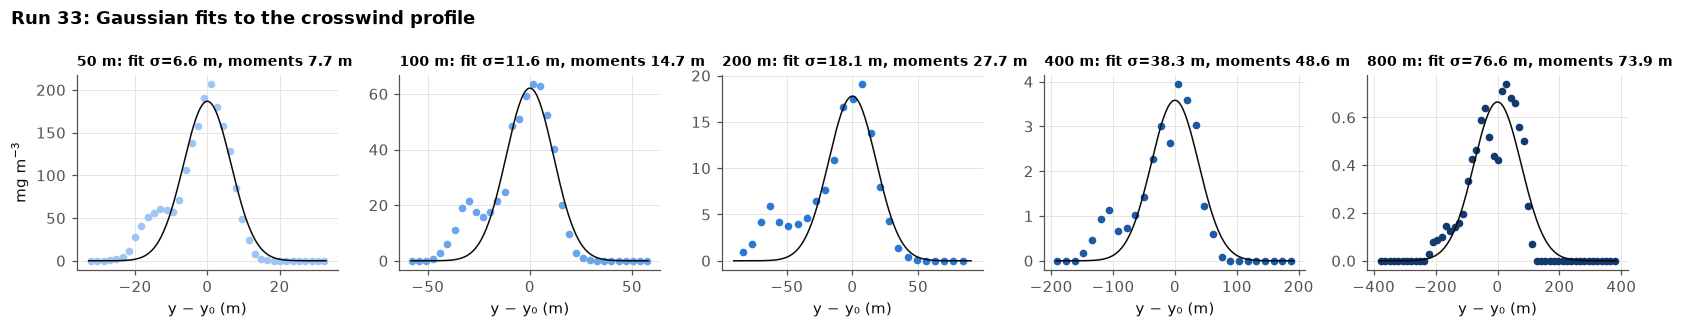

In [3]:
def gauss(y, A, y0, s):
    return A * np.exp(-(y - y0) ** 2 / (2 * s ** 2))

def crosswind(run, arc):
    d = arcs[(arcs.run == run) & (arcs.arc_m == arc) & arcs.status.isin(["value", "not_measurable"])].sort_values("post")
    y = arc * np.deg2rad(d.bearing_unwrapped.to_numpy(float))
    return y, d.concentration_mg_m3.fillna(0).to_numpy(float)

def fit_gauss(y, c):
    w = c / c.sum(); y0 = (w * y).sum(); s = np.sqrt((w * (y - y0) ** 2).sum())
    p, _ = curve_fit(gauss, y, c, p0=[c.max(), y0, max(s, 1)], maxfev=5000)
    return p

RUN = "33"
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, arc in zip(axes, pgdata.ARCS_M):
    y, c = crosswind(RUN, arc); A, y0, s = fit_gauss(y, c)
    m = (np.abs(y - y0) < 5 * abs(s))
    ax.plot(y[m] - y0, c[m], "o", ms=4, color=pgdata.ARC_COLORS[arc])
    yy = np.linspace(-5 * abs(s), 5 * abs(s), 200); ax.plot(yy, gauss(yy, A, 0, s), color=pgdata.INK, lw=1)
    sy = summ.query("run == @RUN and arc_m == @arc").sigma_y_m.iloc[0]
    ax.set_title(f"{arc} m: fit σ={abs(s):.1f} m, moments {sy:.1f} m", fontsize=9); ax.set_xlabel("y − y₀ (m)")
axes[0].set_ylabel("mg m$^{-3}$"); fig.suptitle(f"Run {RUN}: Gaussian fits to the crosswind profile", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

The Gaussian shape is a good approximation, though not a perfect one: the tails are often a
little heavier. Fitted and moment widths agree closely. The moment width needs no fit and never
fails, so we use it from here on.

## 2. σ_y grows with distance, and stability sets how fast

   convective:  sigma_y ≈ 0.376 · x^0.83
 near-neutral:  sigma_y ≈ 0.312 · x^0.70
       stable:  sigma_y ≈ 0.241 · x^0.74


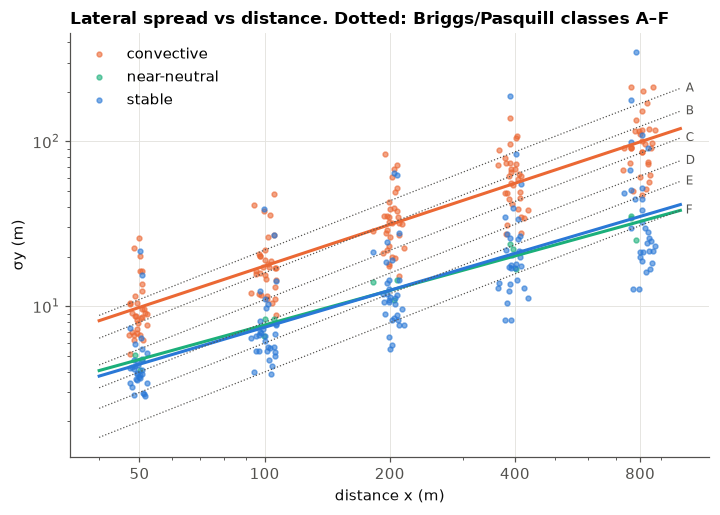

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for reg, g in summ.dropna(subset=["regime"]).groupby("regime", observed=True):
    ax.scatter(g.arc_m * np.exp(np.random.default_rng(0).normal(0, 0.04, len(g))), g.sigma_y_m, s=10, alpha=0.6, color=colors[reg], label=reg)
    b, a = np.polyfit(np.log(g.arc_m), np.log(g.sigma_y_m), 1)
    xx = np.array([40, 1000]); ax.plot(xx, np.exp(a) * xx ** b, color=colors[reg], lw=2)
    print(f"{reg:>13}:  sigma_y ≈ {np.exp(a):.3f} · x^{b:.2f}")
# Briggs (1973) open-country curves, Pasquill classes A (most unstable) .. F (most stable)
x = np.geomspace(40, 1000, 50)
for cls, c in zip("ABCDEF", [.22, .16, .11, .08, .06, .04]):
    ax.plot(x, c * x / np.sqrt(1 + 1e-4 * x), color=pgdata.MUTED, lw=0.8, ls=":")
    ax.text(1030, c * 1000 / np.sqrt(1.1), cls, color=pgdata.MUTED, fontsize=8, va="center")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(pgdata.ARCS_M, pgdata.ARCS_M)
ax.set_xlabel("distance x (m)"); ax.set_ylabel("σy (m)"); ax.legend()
ax.set_title("Lateral spread vs distance. Dotted: Briggs/Pasquill classes A–F"); plt.show()

The convective plumes follow the Pasquill **A–C** curves. The stable ones start near **D** at
50–100 m and drift towards **E–F** by 800 m, because they grow more slowly (exponent ≈ 0.74,
against 0.83 for convective runs). Not bad for curves partly derived from this same experiment.

### Taylor's theory: σ_y ≈ σ_θ · x

G. I. Taylor (1921) showed that close to the source, before the plume has "forgotten" its
starting direction, the plume width is just the swing of the wind times the distance:
$\sigma_y \approx \sigma_\theta x$, with σ_θ in radians. Further away, the growth slows. This
is a physically motivated **association** that we can test directly, since the vane and the
samplers are independent.

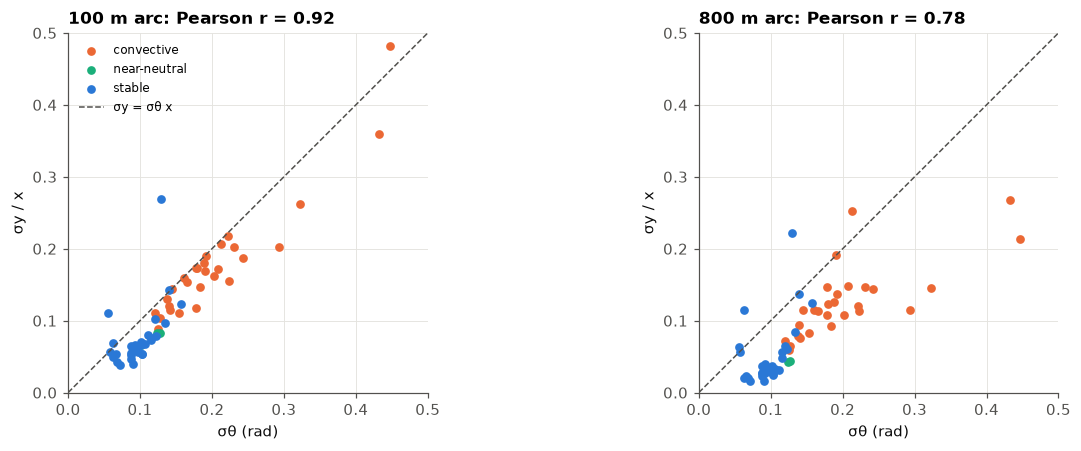

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, arc in zip(axes, [100, 800]):
    d = summ[summ.arc_m == arc].dropna(subset=["sigma_theta_source_10", "regime"])
    st = np.deg2rad(d.sigma_theta_source_10)
    for reg, g in d.groupby("regime", observed=True):
        ax.scatter(np.deg2rad(g.sigma_theta_source_10), g.sigma_y_m / arc, color=colors[reg], s=22, label=reg)
    lim = [0, 0.5]; ax.plot(lim, lim, color=pgdata.MUTED, ls="--", lw=1, label="σy = σθ x")
    r = np.corrcoef(st, d.sigma_y_m / arc)[0, 1]
    ax.set_title(f"{arc} m arc: Pearson r = {r:.2f}"); ax.set_xlabel("σθ (rad)"); ax.set_ylabel("σy / x")
    ax.set_xlim(0, .5); ax.set_ylim(0, .5); ax.set_aspect("equal")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

At 100 m the points sit near the 1:1 line, as Taylor predicts. At 800 m they fall below it:
the plume has travelled long enough that the slow swings of the wind no longer carry it
sideways as a whole. That is the "growth slows" regime, and it is what the
$(1+10^{-4}x)^{-1/2}$ factor in the Briggs formula represents.

## 3. σ_z from mass conservation

We have no vertical profile on most arcs, but **mass conservation** gives σ_z anyway. All the
gas released (Q, in g/s) must cross each arc, carried by the wind u. Integrating the Gaussian
over y gives the *crosswind-integrated concentration* at the ground:

$$ C_y = \int C\,dy = \frac{2Q}{\sqrt{2\pi}\,u\,\sigma_z} \quad\Rightarrow\quad \sigma_z = \sqrt{\frac{2}{\pi}}\,\frac{Q}{u\,C_y} $$

The factor 2 comes from ground reflection. It is a beautiful trick, with one weakness: **u**.
Which wind speed carries a plume that is 1 m deep at 50 m and 20 m deep at 800 m? We use the
2 m speed. That biases σ_z at long range, where the plume rides faster air aloft.

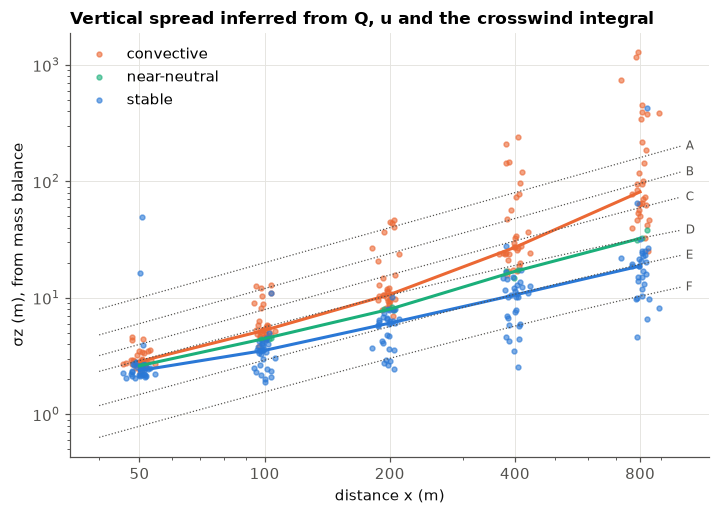

In [6]:
summ["Cy_g_m2"] = summ.cwic / 1000.0            # mg m-2 -> g m-2
summ["sigma_z_mb"] = np.sqrt(2 / np.pi) * summ.Q_g_s / (summ.u_ref * summ.Cy_g_m2)
fig, ax = plt.subplots(figsize=(7.5, 5))
for reg, g in summ.dropna(subset=["regime", "sigma_z_mb"]).groupby("regime", observed=True):
    ax.scatter(g.arc_m * np.exp(np.random.default_rng(1).normal(0, 0.04, len(g))), g.sigma_z_mb, s=10, alpha=0.6, color=colors[reg], label=reg)
    med = g.groupby("arc_m").sigma_z_mb.median(); ax.plot(med.index, med.values, color=colors[reg], lw=2)
briggs_z = {"A": lambda x: .20 * x, "B": lambda x: .12 * x, "C": lambda x: .08 * x / np.sqrt(1 + 2e-4 * x),
            "D": lambda x: .06 * x / np.sqrt(1 + 1.5e-3 * x), "E": lambda x: .03 * x / (1 + 3e-4 * x), "F": lambda x: .016 * x / (1 + 3e-4 * x)}
for cls, f in briggs_z.items():
    ax.plot(x, f(x), color=pgdata.MUTED, lw=0.8, ls=":"); ax.text(1030, f(1000), cls, color=pgdata.MUTED, fontsize=8, va="center")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(pgdata.ARCS_M, pgdata.ARCS_M)
ax.set_xlabel("distance x (m)"); ax.set_ylabel("σz (m), from mass balance"); ax.legend()
ax.set_title("Vertical spread inferred from Q, u and the crosswind integral"); plt.show()

### Cross-check with the towers

At 100 m we *can* see the vertical profile: six towers, samplers from 0.5 to 17.5 m. For a
ground-level Gaussian, $\ln C$ is linear in $z^2$ with slope $-1/(2\sigma_z^2)$. We fit that,
pooling the towers with one intercept per tower, and compare with the mass-balance σ_z at 100 m.
Two independent routes to the same number make a good test of the model.

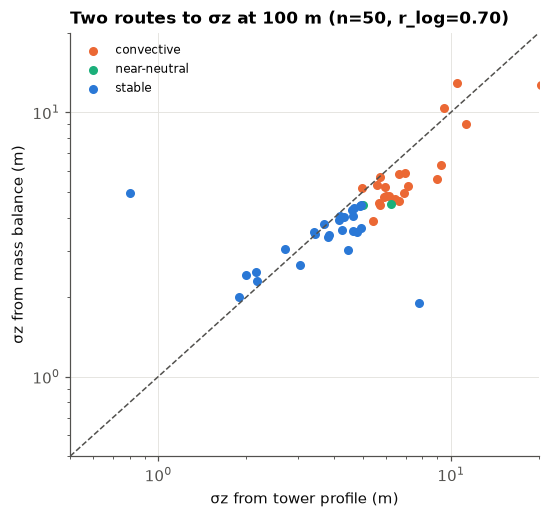

In [7]:
def tower_sigma_z(run):
    d = towers[(towers.run == run) & (towers.status == "value") & (towers.concentration_mg_m3 > 0)]
    d = d[d.groupby("tower").height_m.transform("size") >= 3]
    if d.tower.nunique() == 0:
        return np.nan
    X = np.column_stack([d.height_m ** 2] + [(d.tower == t).astype(float) for t in sorted(d.tower.unique())])
    coef, *_ = np.linalg.lstsq(X, np.log(d.concentration_mg_m3), rcond=None)
    return np.sqrt(-1 / (2 * coef[0])) if coef[0] < 0 else np.nan

tw = pd.Series({r: tower_sigma_z(r) for r in towers.run.unique()}, name="sigma_z_tower")
cmp = summ[summ.arc_m == 100].set_index("run")[["sigma_z_mb", "regime"]].join(tw, how="inner").dropna()
fig, ax = plt.subplots(figsize=(5.5, 5))
for reg, g in cmp.groupby("regime", observed=True):
    ax.scatter(g.sigma_z_tower, g.sigma_z_mb, color=colors[reg], s=24, label=reg)
lim = [0.5, 20]; ax.plot(lim, lim, color=pgdata.MUTED, ls="--", lw=1)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("σz from tower profile (m)"); ax.set_ylabel("σz from mass balance (m)")
r = np.corrcoef(np.log(cmp.sigma_z_tower), np.log(cmp.sigma_z_mb))[0, 1]
ax.set_title(f"Two routes to σz at 100 m (n={len(cmp)}, r_log={r:.2f})"); ax.legend(fontsize=8); plt.show()

The two estimates track each other across an order of magnitude, from shallow stable plumes to
deep convective ones. The scatter around the line is mostly the wind-speed choice in the mass
balance, plus the fact that a ground-source vertical profile is not quite Gaussian (it is closer
to $e^{-z^{1.5}}$, a known Prairie Grass result).

## 4. A simple statistical model of the peak concentration

Finally, a predictive model. Dimensional reasoning says $C_{max} u / Q$ depends only on distance
and on the state of turbulence. We regress

$$ \log_{10}\!\left(\frac{C_{max}\,u}{Q}\right) = a + b\,\log_{10}x + c\cdot[\text{stable}] + d\cdot[\text{stable}]\log_{10}x $$

with ordinary least squares (numpy only). The stable regime gets its own intercept and its own
slope.

**Validation.** Arcs from the same run share their weather, so a random split of rows would
leak information. We use **leave-one-run-out** cross-validation: we predict each run's five
arcs from a model fitted on all *other* runs.

In [8]:
m = summ.dropna(subset=["regime", "u_ref"]).copy()
m = m[m.peak > 0]
m["y"] = np.log10(m.peak / 1000 * m.u_ref / m.Q_g_s)      # m^-2
m["lx"] = np.log10(m.arc_m)
m["stable"] = (m.regime == "stable").astype(float)

def design(d):
    return np.column_stack([np.ones(len(d)), d.lx, d.stable, d.stable * d.lx])

coef, *_ = np.linalg.lstsq(design(m), m.y, rcond=None)
pred_in = design(m) @ coef
pred_cv = pd.Series(index=m.index, dtype=float)
for run in m.run.unique():
    tr, te = m.run != run, m.run == run
    c, *_ = np.linalg.lstsq(design(m[tr]), m.y[tr], rcond=None)
    pred_cv[te] = design(m[te]) @ c
r2 = lambda p: 1 - ((m.y - p) ** 2).sum() / ((m.y - m.y.mean()) ** 2).sum()
print(pd.Series(coef, index=["a", "b (log x)", "c (stable)", "d (stable × log x)"]).round(3).to_string())
print(f"\nR² in-sample {r2(pred_in):.3f}   leave-one-run-out {r2(pred_cv):.3f}")
print(f"typical error (CV): factor {10 ** np.sqrt(((m.y - pred_cv) ** 2).mean()):.2f}")

a                     1.651
b (log x)            -2.050
c (stable)           -0.811
d (stable × log x)    0.668

R² in-sample 0.827   leave-one-run-out 0.817
typical error (CV): factor 2.47


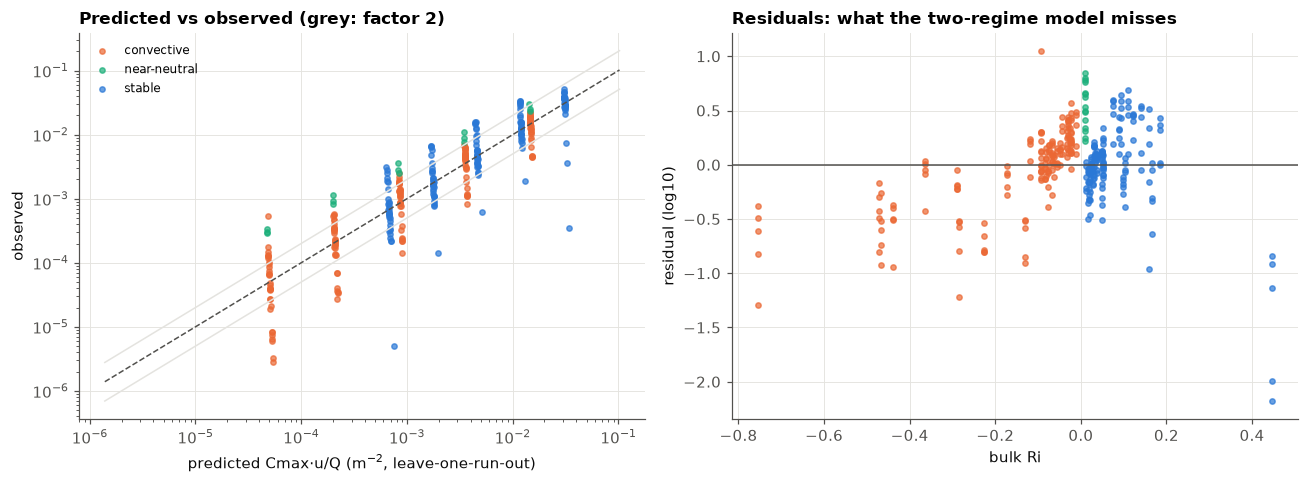

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
for reg, g in m.groupby("regime", observed=True):
    ax.scatter(10 ** pred_cv[g.index], 10 ** g.y, s=12, color=colors[reg], label=reg, alpha=0.7)
lim = [10 ** m.y.min() / 2, 10 ** m.y.max() * 2]
ax.plot(lim, lim, color=pgdata.MUTED, ls="--", lw=1)
ax.plot(lim, np.array(lim) * 2, color=pgdata.GRID, lw=1); ax.plot(lim, np.array(lim) / 2, color=pgdata.GRID, lw=1)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("predicted Cmax·u/Q (m$^{-2}$, leave-one-run-out)")
ax.set_ylabel("observed"); ax.set_title("Predicted vs observed (grey: factor 2)"); ax.legend(fontsize=8)
ax = axes[1]
res = m.y - pred_cv
for reg, g in m.groupby("regime", observed=True):
    ax.scatter(g.Ri_b, res[g.index], s=12, color=colors[reg], alpha=0.7)
ax.axhline(0, color=pgdata.MUTED, lw=1); ax.set_xlabel("bulk Ri"); ax.set_ylabel("residual (log10)")
ax.set_title("Residuals: what the two-regime model misses"); plt.tight_layout(); plt.show()

**Reading the result**

- In convective conditions the normalised peak falls as $x^{-2.06}$. That is almost exactly the
  $x^{-2}$ that the Gaussian formula predicts if σ_y and σ_z both grow linearly with x.
- Stable plumes decay much more slowly, as $x^{-1.4}$ (b + d). They are about 2× more
  concentrated than convective plumes at 50 m, and about 14× at 800 m. This is why night-time
  releases are the worst case for downwind exposure.
- The leave-one-run-out R² (0.81) is almost the in-sample R² (0.82), so the model is not
  overfitting. The RMS error is a factor of about 2.5. Within a factor of 2 counts as good in
  dispersion modelling, so this crude two-class model sits not far outside that.
- The residuals still trend with Ri *within* the convective regime: the most convective runs
  (Ri < −0.2) are over-predicted, by up to a factor of 10. A two-class switch is coarse. A
  continuous stability measure (Ri, or the Obukhov length) is an obvious upgrade, and so is
  Pasquill-class σ curves fed back into the Gaussian formula.

**Ideas to extend this notebook**

- Use `arc_summary(corrected=True)` to apply the Table 5.4 evaporation corrections and see what changes.
- Replace the regime dummy with Ri_b, or with σ_θ, and compare the cross-validated R².
- Fit a stretched exponential $e^{-(z/\ell)^s}$ to the tower profiles and estimate *s*.